# Notebook 02 — Object Detection

**Objective.** Detect traffic-related objects in video frames with a pretrained detector, and produce structured detections that a tracker (Notebook 03) can consume.

**Background.** Detection answers *what is where* in a single frame: a list of boxes, each with a class and a confidence. It knows nothing about time; linking boxes across frames is tracking's job. Every later stage depends on detection quality: a missed motorcycle cannot be tracked, and a box on the wrong object becomes a false trajectory.

**Input.**
- `data/video-test.mp4` (primary sample; 1920×1080, 59.94 FPS, 900 frames), read with the validated `traffic_violation_detection.video` module.
- Pretrained COCO weights from Ultralytics, downloaded to `weights/` (git-ignored).

**Output.**
- Per-frame detection records following the **Detection Data** contract, written to `outputs/02_object_detection/detections/video-test.jsonl`, with the exact detector configuration next to them.
- Annotated frames, an annotated video, and per-class statistics.
- `annotate_video`, a function from any video to a copy with its boxes drawn, saved as `<video name>_output.mp4` (section 9).
- Qualitative quality observations and measured inference performance.

**Runs on the GPU server.** Inference uses CUDA; the notebook stops early if no GPU is visible. Use the `Python (tvd)` kernel with the `detection` extra installed (`pip install -e ".[notebooks,detection]"`).

## 0. Setup

In [1]:
import json
import platform
import statistics
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import ultralytics
from ultralytics import YOLO

from traffic_violation_detection.video import iter_frames, read_frame_at, read_video_metadata

%config InlineBackend.figure_formats = ["jpeg"]

assert torch.cuda.is_available(), "This notebook needs a CUDA GPU (run it on the GPU server)"
print("Python     :", platform.python_version())
print("PyTorch    :", torch.__version__, "| CUDA runtime", torch.version.cuda)
print("GPU        :", torch.cuda.get_device_name(0))
print("Ultralytics:", ultralytics.__version__, "| OpenCV", cv2.__version__)

Python     : 3.11.18
PyTorch    : 2.15.0+cu132 | CUDA runtime 13.2
GPU        : NVIDIA GeForce RTX 4090
Ultralytics: 8.4.197 | OpenCV 5.0.0


In [2]:
def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"No pyproject.toml found in {start} or any parent directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SAMPLE_VIDEO = PROJECT_ROOT / "data" / "video-test.mp4"
WEIGHTS_DIR = PROJECT_ROOT / "weights"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "02_object_detection"
WEIGHTS_DIR.mkdir(exist_ok=True)
(OUTPUT_DIR / "detections").mkdir(parents=True, exist_ok=True)

sample_meta = read_video_metadata(SAMPLE_VIDEO)
print({k: v for k, v in sample_meta.items() if k != "path"})

{'video_id': 'video-test', 'fps': 59.94005994005994, 'reported_frame_count': 900, 'width': 1920, 'height': 1080, 'reported_duration_s': 15.015}


## 1. Concepts

- **Bounding box.** An axis-aligned rectangle around an object. Here it is always `[x1, y1, x2, y2]` in **pixels of the original frame**: top-left and bottom-right corners, with the origin at the image's top-left and *y* pointing down. Other common formats exist, such as `[x, y, w, h]` or values normalized to 0–1, so the format is part of the contract.
- **Class label.** The detector was trained on **COCO**, a dataset with 80 everyday classes. Only some are traffic-related: `person`, `bicycle`, `car`, `motorcycle`, `bus`, `truck`, and `traffic light`. COCO has no class for license plates, and none that separates a pedestrian from a rider.
- **Confidence.** A score in [0, 1] for "this box contains this class". It is not a calibrated probability. A **confidence threshold** trades missed objects (threshold too high) against false boxes (threshold too low).
- **Non-Maximum Suppression (NMS).** A detector predicts many overlapping boxes for the same object. NMS keeps the highest-confidence box and removes others of the same class whose overlap with it exceeds an **IoU threshold**. Section 4 implements it from scratch.
- **IoU (Intersection over Union).** The area of overlap divided by the area of union of two boxes: 0 means disjoint, 1 means identical.
- **Input size (`imgsz`).** The network sees a resized copy of the frame. At `imgsz=640`, a 1920×1080 frame shrinks by 3×, so a 30-pixel motorcycle in the distance becomes 10 pixels. Larger inputs find smaller objects but cost more compute.

## 2. Choosing a pretrained detector

**Candidates.** All of these are pretrained on COCO and available through Ultralytics 8.4, so they can be compared with the same code:

| Family | Notes |
| --- | --- |
| **YOLO11** (n/s/m/l/x) | Mature, widely documented one-stage detector; uses NMS. |
| **YOLO26** (n/s/m/l/x) | Newest Ultralytics family. In this version it also runs with NMS (`end2end` is off). |
| **RT-DETR** (l/x) | Transformer-based, NMS-free by design; larger and slower. |

Detectors outside Ultralytics, such as torchvision's Faster R-CNN or RF-DETR, were not tried in this baseline.

**License.** Ultralytics code and weights are licensed under **AGPL-3.0**, while this repository is MIT. This is acceptable for an academic experiment. Distributing the system, or offering it as a network service, would bring AGPL obligations, so a permissively licensed detector should be considered before any such use.

**Experiment.** Without ground-truth labels we cannot measure accuracy yet; that is Notebook 09's job. What we *can* measure is speed, and how many plausible objects each configuration reports on the same frames. The counts are only a rough proxy for recall: more boxes may also mean more false positives. They still show the effect of model size and input resolution clearly.

In [3]:
TRAFFIC_CLASSES = {0: "person", 1: "bicycle", 2: "car", 3: "motorcycle", 5: "bus", 7: "truck", 9: "traffic light"}
COMPARE_FRAMES = [0, 225, 450, 675, 899]
compare_images = [read_frame_at(SAMPLE_VIDEO, k)["image"] for k in COMPARE_FRAMES]


def load_detector(weights_name: str) -> YOLO:
    # Ultralytics downloads known weights to the given path on first use.
    return YOLO(str(WEIGHTS_DIR / weights_name))


def timed_predict(model, image, **kwargs):
    torch.cuda.synchronize()
    start = time.perf_counter()
    result = model.predict(image, verbose=False, **kwargs)[0]
    torch.cuda.synchronize()
    return result, (time.perf_counter() - start) * 1000


comparison = []
for weights_name in ["yolo11s.pt", "yolo11m.pt", "yolo11l.pt", "yolo26s.pt", "yolo26m.pt", "yolo26l.pt"]:
    model = load_detector(weights_name)
    for imgsz in (640, 1280):
        model.predict(compare_images[0], imgsz=imgsz, verbose=False)  # warm-up: first call allocates GPU memory
        times, counts = [], {name: 0 for name in TRAFFIC_CLASSES.values()}
        for image in compare_images:
            result, ms = timed_predict(model, image, imgsz=imgsz, conf=0.25, classes=list(TRAFFIC_CLASSES))
            times.append(ms)
            for class_id in result.boxes.cls.int().tolist():
                counts[TRAFFIC_CLASSES[class_id]] += 1
        comparison.append({"weights": weights_name, "imgsz": imgsz, "ms_per_frame": statistics.median(times),
                           **{k: v / len(compare_images) for k, v in counts.items()}})
    del model
    torch.cuda.empty_cache()

header = ["weights", "imgsz", "ms_per_frame", "motorcycle", "person", "car", "bus", "truck", "bicycle", "traffic light"]
print(" | ".join(f"{h:>13}" for h in header))
for row in comparison:
    print(" | ".join(f"{row[h]:>13.1f}" if isinstance(row[h], float) else f"{row[h]:>13}" for h in header))
print(f"\nMean detections per frame over frames {COMPARE_FRAMES} (conf >= 0.25); ms = median end-to-end predict() call.")

      weights |         imgsz |  ms_per_frame |    motorcycle |        person |           car |           bus |         truck |       bicycle | traffic light
   yolo11s.pt |           640 |          11.2 |          16.6 |          14.0 |           9.2 |           1.0 |           0.2 |           0.0 |           0.2
   yolo11s.pt |          1280 |          13.5 |          27.4 |          28.6 |          13.0 |           1.0 |           0.8 |           0.0 |           0.4
   yolo11m.pt |           640 |          12.3 |          21.4 |          16.6 |           9.2 |           1.0 |           0.6 |           0.0 |           0.2
   yolo11m.pt |          1280 |          15.7 |          30.8 |          27.2 |          14.2 |           1.0 |           1.4 |           0.0 |           0.0
   yolo11l.pt |           640 |          17.2 |          21.6 |          13.6 |           9.8 |           1.2 |           2.0 |           0.0 |           0.0
   yolo11l.pt |          1280 |          19.5 |     

**Reading the table** (exact numbers are in the output above):

- **Input size matters more than model size here.** For every model, `imgsz=1280` reports far more motorcycles and persons than `640`, because most road users are small at 1080p. Going from *m* to *l* at the same input size changes much less.
- **Speed is not a constraint on the RTX 4090.** All configurations take a few tens of milliseconds per frame or less, including CPU pre- and post-processing. Single-frame timings are noisy, and section 7 measures throughput properly.
- **Traffic lights get only a few low-confidence detections on these five frames.** The signal heads are only about 10–20 px wide (Notebook 00). Section 6 checks them over the whole video.

**Decision for the baseline: `yolo26m.pt` at `imgsz=1280`.**

- The newest model family, at medium size.
- Its detection counts are in the same range as the larger models at 1280.
- It leaves GPU headroom for tracking and plate recognition later.

This is a provisional choice, to be revisited with labeled data in Notebook 09.

In [4]:
DETECTOR_CONFIG = {
    "weights": "yolo26m.pt",
    "imgsz": 1280,
    "conf": 0.10,  # stored threshold: low on purpose, trackers such as ByteTrack use low-score boxes
    "iou": 0.7,    # NMS IoU threshold (Ultralytics default)
    "classes": sorted(TRAFFIC_CLASSES),
    "device": 0,
}
DISPLAY_CONF = 0.25  # threshold for figures and counts in this notebook

model = load_detector(DETECTOR_CONFIG["weights"])
print("Loaded", DETECTOR_CONFIG["weights"], "|", sum(p.numel() for p in model.model.parameters()) / 1e6, "M parameters")
print("Class names used:", {i: model.names[i] for i in DETECTOR_CONFIG["classes"]})

Loaded yolo26m.pt | 21.896248 M parameters
Class names used: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 5: 'bus', 7: 'truck', 9: 'traffic light'}


## 3. Run inference on a single frame and inspect the raw result

We use frame 450 (7.5 s). In Notebook 00 this was the last sampled moment with the distant signal still red.

In [5]:
FRAME_INDEX = 450
frame_record = read_frame_at(SAMPLE_VIDEO, FRAME_INDEX)
frame = frame_record["image"]

result = model.predict(frame, imgsz=DETECTOR_CONFIG["imgsz"], conf=DETECTOR_CONFIG["conf"], iou=DETECTOR_CONFIG["iou"],
                       classes=DETECTOR_CONFIG["classes"], device=DETECTOR_CONFIG["device"], verbose=False)[0]

print("type          :", type(result).__name__)
print("orig_shape    :", result.orig_shape, "(height, width) of the input frame")
print("boxes         :", len(result.boxes))
print("speed (ms)    :", {k: round(v, 1) for k, v in result.speed.items()})
print("boxes.xyxy    :", tuple(result.boxes.xyxy.shape), result.boxes.xyxy.dtype, "on", result.boxes.xyxy.device)
print("first 3 rows  :")
print("  xyxy ", result.boxes.xyxy[:3].cpu().numpy().round(1).tolist())
print("  conf ", result.boxes.conf[:3].cpu().numpy().round(3).tolist())
print("  cls  ", result.boxes.cls[:3].cpu().numpy().tolist())

type          : Results
orig_shape    : (1080, 1920) (height, width) of the input frame
boxes         : 124
speed (ms)    : {'preprocess': 3.3, 'inference': 8.7, 'postprocess': 1.2}
boxes.xyxy    : (124, 4) torch.float32 on cuda:0
first 3 rows  :
  xyxy  [[928.0, 460.5, 1196.5999755859375, 711.5999755859375], [669.2999877929688, 333.29998779296875, 831.0, 453.1000061035156], [84.5999984741211, 416.5, 292.8999938964844, 584.2000122070312]]
  conf  [0.9039999842643738, 0.8970000147819519, 0.8949999809265137]
  cls   [2.0, 2.0, 2.0]


The raw result keeps everything as **tensors on the GPU**: boxes in pixel coordinates of the original frame (`xyxy`), confidences, and class ids as floats. `speed` splits the time into **preprocess** (resize and letterbox on the CPU, upload to the GPU), **inference** (the network), and **postprocess** (NMS and rescaling boxes back to the original frame).

### Extract structured detections (Detection Data contract)

Downstream code should not depend on Ultralytics objects. We convert each result into plain, JSON-serializable dictionaries:

| key | meaning |
| --- | --- |
| `class_id` | COCO class id |
| `class_name` | human-readable class |
| `confidence` | detector score, 0–1 |
| `bbox_xyxy` | `[x1, y1, x2, y2]` in original-frame pixels (floats, rounded to 0.01 px) |

A frame-level record adds `video_id`, `frame_index`, `timestamp_s`, `width`, and `height` from the Frame Data record.

In [6]:
def predict(model, image: np.ndarray, config: dict):
    # One Ultralytics prediction on one BGR frame, with all settings taken from the config.
    return model.predict(image, imgsz=config["imgsz"], conf=config["conf"], iou=config["iou"],
                         classes=config["classes"], device=config["device"], verbose=False)[0]


def to_detections(result, names: dict) -> list[dict]:
    # Convert an Ultralytics result into plain, JSON-serializable detection dictionaries.
    boxes = result.boxes
    return [
        {
            "class_id": int(class_id),
            "class_name": names[int(class_id)],
            "confidence": round(float(confidence), 4),
            "bbox_xyxy": [round(float(v), 2) for v in xyxy],
        }
        for xyxy, confidence, class_id in zip(boxes.xyxy.tolist(), boxes.conf.tolist(), boxes.cls.tolist())
    ]


def detect(model, image: np.ndarray, config: dict) -> list[dict]:
    return to_detections(predict(model, image, config), model.names)


detections = detect(model, frame, DETECTOR_CONFIG)
print(len(detections), "detections; first two:")
for d in detections[:2]:
    print(" ", d)

counts = {}
for d in detections:
    if d["confidence"] >= DISPLAY_CONF:
        counts[d["class_name"]] = counts.get(d["class_name"], 0) + 1
print(f"\nPer class (conf >= {DISPLAY_CONF}):", dict(sorted(counts.items(), key=lambda kv: -kv[1])))

124 detections; first two:
  {'class_id': 2, 'class_name': 'car', 'confidence': 0.9045, 'bbox_xyxy': [927.98, 460.49, 1196.64, 711.6]}
  {'class_id': 2, 'class_name': 'car', 'confidence': 0.8975, 'bbox_xyxy': [669.33, 333.27, 830.95, 453.14]}

Per class (conf >= 0.25): {'person': 29, 'motorcycle': 29, 'car': 16, 'truck': 3, 'bus': 1, 'traffic light': 1}


### Draw the detections

Each class gets its own color. Labels show class and confidence. Only boxes at or above the display threshold are drawn.

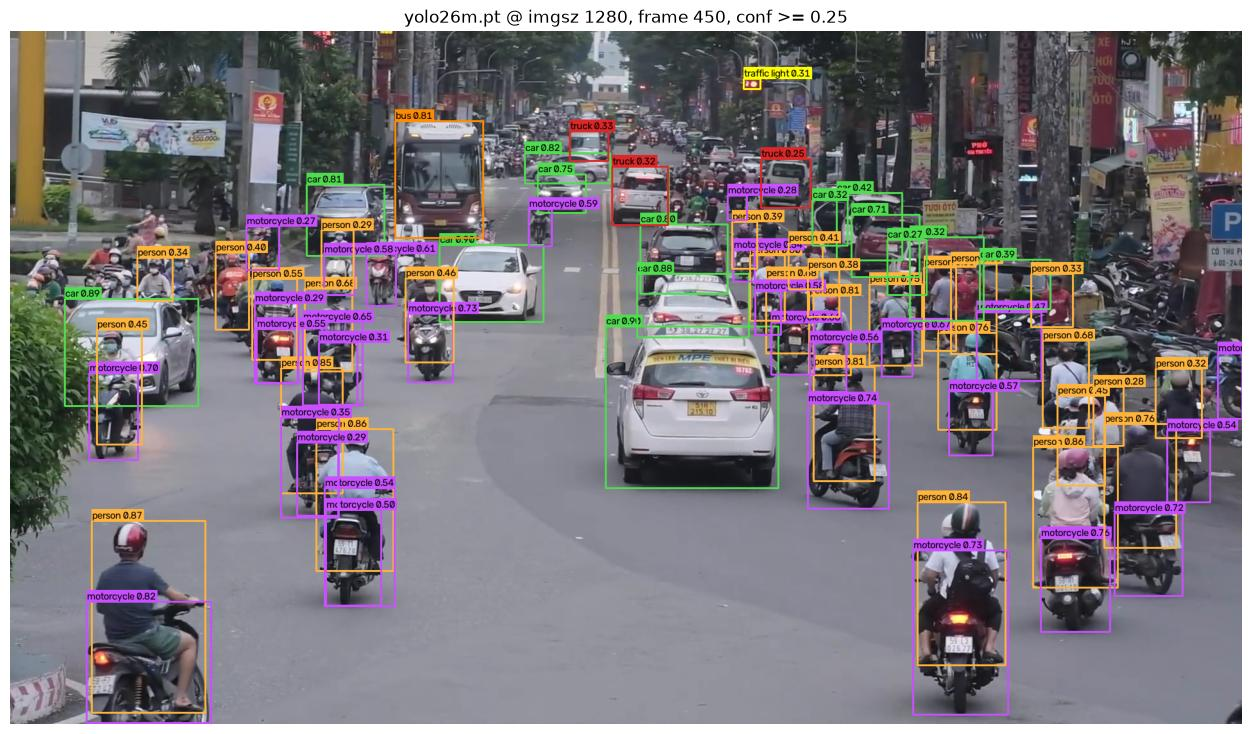

In [7]:
CLASS_COLORS_BGR = {
    "person": (60, 180, 255), "bicycle": (255, 200, 0), "car": (80, 220, 80), "motorcycle": (255, 80, 200),
    "bus": (0, 140, 255), "truck": (40, 40, 220), "traffic light": (0, 255, 255),
}


def draw_detections(image: np.ndarray, detections: list[dict], min_conf: float = DISPLAY_CONF, thickness: int = 2) -> np.ndarray:
    # Return a copy of the BGR image with boxes and labels drawn (OpenCV points are (x, y) integers).
    canvas = image.copy()
    for d in detections:
        if d["confidence"] < min_conf:
            continue
        x1, y1, x2, y2 = (int(round(v)) for v in d["bbox_xyxy"])
        color = CLASS_COLORS_BGR.get(d["class_name"], (255, 255, 255))
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, thickness)
        label = f"{d['class_name']} {d['confidence']:.2f}"
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(canvas, (x1, max(0, y1 - th - 4)), (x1 + tw + 2, y1), color, -1)
        cv2.putText(canvas, label, (x1 + 1, y1 - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return canvas


annotated = draw_detections(frame, detections)
cv2.imwrite(str(OUTPUT_DIR / f"frame_{FRAME_INDEX}_detections.jpg"), annotated)

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
ax.set_title(f"{DETECTOR_CONFIG['weights']} @ imgsz {DETECTOR_CONFIG['imgsz']}, frame {FRAME_INDEX}, conf >= {DISPLAY_CONF}")
ax.axis("off")
plt.show()

## 4. Non-Maximum Suppression from scratch

To understand what the postprocessing step does, we re-implement **class-aware greedy NMS**:

1. Sort the boxes by confidence.
2. Repeatedly keep the best remaining box.
3. Drop every remaining box of the **same class** whose IoU with it exceeds the threshold.

To get *candidate* boxes, we run the detector with an IoU threshold of 0.95, so almost nothing is suppressed. Our NMS at 0.7 should then reproduce the detector's own output at 0.7.

In [8]:
def iou_matrix(boxes_a: np.ndarray, boxes_b: np.ndarray) -> np.ndarray:
    # Pairwise IoU between two arrays of [x1, y1, x2, y2] boxes.
    x1 = np.maximum(boxes_a[:, None, 0], boxes_b[None, :, 0])
    y1 = np.maximum(boxes_a[:, None, 1], boxes_b[None, :, 1])
    x2 = np.minimum(boxes_a[:, None, 2], boxes_b[None, :, 2])
    y2 = np.minimum(boxes_a[:, None, 3], boxes_b[None, :, 3])
    intersection = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (boxes_a[:, 2] - boxes_a[:, 0]) * (boxes_a[:, 3] - boxes_a[:, 1])
    area_b = (boxes_b[:, 2] - boxes_b[:, 0]) * (boxes_b[:, 3] - boxes_b[:, 1])
    return intersection / (area_a[:, None] + area_b[None, :] - intersection)


def nms(boxes: np.ndarray, scores: np.ndarray, classes: np.ndarray, iou_threshold: float) -> list[int]:
    # Class-aware greedy NMS; returns indices of kept boxes, best first.
    order = list(np.argsort(-scores))
    keep = []
    while order:
        best = order.pop(0)
        keep.append(best)
        if not order:
            break
        rest = np.array(order)
        overlaps = iou_matrix(boxes[best:best + 1], boxes[rest])[0]
        suppressed = (overlaps > iou_threshold) & (classes[rest] == classes[best])
        order = [i for i, s in zip(order, suppressed) if not s]
    return keep


# A tiny hand-made example: two overlapping cars and one motorcycle on top of them.
toy_boxes = np.array([[10, 10, 110, 60], [14, 12, 112, 64], [20, 20, 60, 90]], dtype=float)
toy_scores = np.array([0.9, 0.8, 0.7])
toy_classes = np.array([2, 2, 3])
print("IoU(car A, car B):", iou_matrix(toy_boxes[:1], toy_boxes[1:2]).round(3)[0, 0])
print("kept:", nms(toy_boxes, toy_scores, toy_classes, 0.7), "-> car B suppressed; the motorcycle survives because it is another class")

IoU(car A, car B): 0.84
kept: [np.int64(0), np.int64(2)] -> car B suppressed; the motorcycle survives because it is another class


In [9]:
def boxes_of(detections):
    return (np.array([d["bbox_xyxy"] for d in detections], dtype=float),
            np.array([d["confidence"] for d in detections]),
            np.array([d["class_id"] for d in detections]))


candidates = detect(model, frame, {**DETECTOR_CONFIG, "iou": 0.95})
cand_boxes, cand_scores, cand_classes = boxes_of(candidates)
ours = [candidates[i] for i in nms(cand_boxes, cand_scores, cand_classes, DETECTOR_CONFIG["iou"])]

model_boxes, _, model_classes = boxes_of(detections)
our_boxes, _, our_classes = boxes_of(ours)
pairwise = iou_matrix(model_boxes, our_boxes)
same_class = model_classes[:, None] == our_classes[None, :]
matched = int(((pairwise > 0.99) & same_class).any(axis=1).sum())

nms_agreement = matched / len(detections)
print(f"candidates (iou=0.95)          : {len(candidates)}")
print(f"our NMS at iou={DETECTOR_CONFIG['iou']}            : {len(ours)}")
print(f"detector's own NMS at iou={DETECTOR_CONFIG['iou']}  : {len(detections)}")
print(f"detector boxes reproduced by ours (same class, IoU > 0.99): {matched}/{len(detections)} = {nms_agreement:.1%}")

candidates (iou=0.95)          : 300
our NMS at iou=0.7            : 124
detector's own NMS at iou=0.7  : 124
detector boxes reproduced by ours (same class, IoU > 0.99): 124/124 = 100.0%


Small differences would be expected, for two reasons:

- Our candidates are not the raw network output. A few boxes were already merged at IoU 0.95, and if the candidate count equals 300, the list was also truncated by Ultralytics' `max_det` limit (default 300).
- Greedy NMS depends on processing order.

Either way, NMS is a simple, explainable rule; nothing learned happens in this step.

**Effect of the two thresholds.** NMS removes duplicates; the confidence threshold removes weak boxes. The sweep below shows how many boxes survive as each is varied on the same frame.

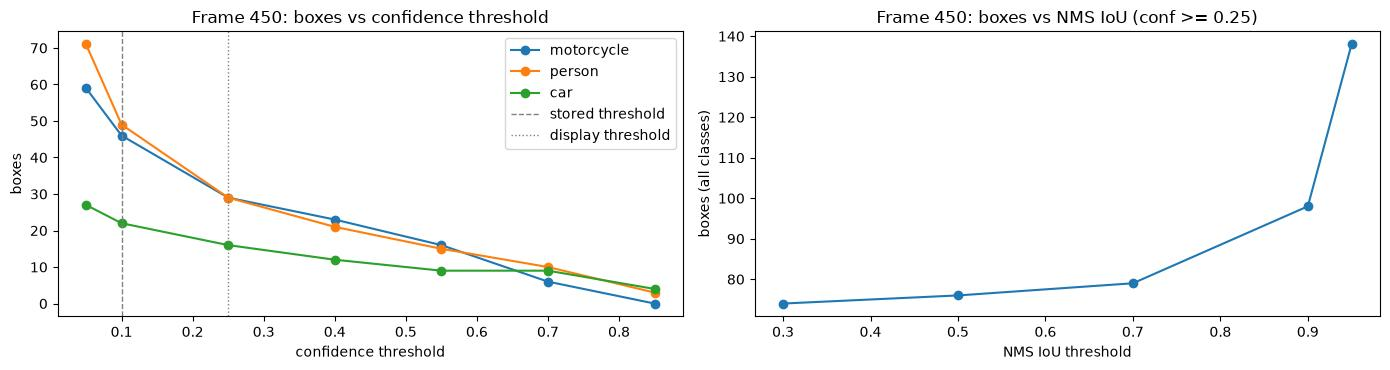

In [10]:
conf_values = [0.05, 0.1, 0.25, 0.4, 0.55, 0.7, 0.85]
iou_values = [0.3, 0.5, 0.7, 0.9, 0.95]
conf_counts = {name: [] for name in ["motorcycle", "person", "car"]}
for c in conf_values:
    kept = detect(model, frame, {**DETECTOR_CONFIG, "conf": c})
    for name in conf_counts:
        conf_counts[name].append(sum(d["class_name"] == name for d in kept))
iou_counts = [len(detect(model, frame, {**DETECTOR_CONFIG, "iou": i, "conf": DISPLAY_CONF})) for i in iou_values]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for name, values in conf_counts.items():
    axes[0].plot(conf_values, values, marker="o", label=name)
axes[0].axvline(DETECTOR_CONFIG["conf"], color="grey", linestyle="--", linewidth=1, label="stored threshold")
axes[0].axvline(DISPLAY_CONF, color="grey", linestyle=":", linewidth=1, label="display threshold")
axes[0].set(xlabel="confidence threshold", ylabel="boxes", title=f"Frame {FRAME_INDEX}: boxes vs confidence threshold")
axes[0].legend()
axes[1].plot(iou_values, iou_counts, marker="o")
axes[1].set(xlabel="NMS IoU threshold", ylabel="boxes (all classes)", title=f"Frame {FRAME_INDEX}: boxes vs NMS IoU (conf >= {DISPLAY_CONF})")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "threshold_sweeps.png", dpi=100)
plt.show()

## 5. Where does the detector struggle? (single frame, zoomed)

Full frames hide the details, so we zoom into three regions of frame 450, at native resolution, with boxes drawn:

- **Near field** — large, dense motorcycles.
- **Far field** — small vehicles queued toward the intersection.
- **Signal region** — the distant traffic signal (region from Notebook 00).

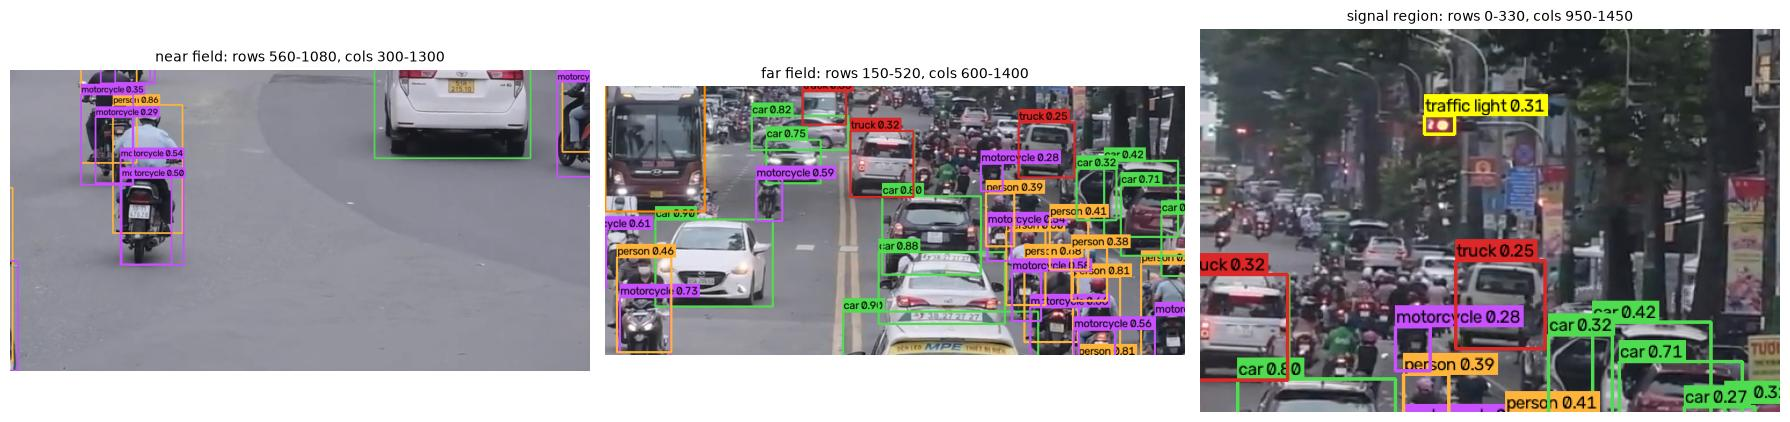

traffic-light detections in this frame (any confidence >= stored threshold): [{'class_id': 9, 'class_name': 'traffic light', 'confidence': 0.3086, 'bbox_xyxy': [1142.86, 73.91, 1168.58, 90.4]}, {'class_id': 9, 'class_name': 'traffic light', 'confidence': 0.2237, 'bbox_xyxy': [1141.16, 72.42, 1176.69, 91.29]}, {'class_id': 9, 'class_name': 'traffic light', 'confidence': 0.1479, 'bbox_xyxy': [1140.51, 72.5, 1171.03, 97.22]}]


In [11]:
REGIONS = {
    "near field": (slice(560, 1080), slice(300, 1300)),
    "far field": (slice(150, 520), slice(600, 1400)),
    "signal region": (slice(0, 330), slice(950, 1450)),
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (rows, cols)) in zip(axes, REGIONS.items()):
    ax.imshow(cv2.cvtColor(annotated[rows, cols], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}: rows {rows.start}-{rows.stop}, cols {cols.start}-{cols.stop}", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / f"frame_{FRAME_INDEX}_zoomed_regions.jpg", dpi=100)
plt.show()

traffic_lights = [d for d in detections if d["class_name"] == "traffic light"]
print("traffic-light detections in this frame (any confidence >= stored threshold):", traffic_lights or "none")

### Riders are detected as `person`

Most `person` boxes in this scene are **riders**, not pedestrians. COCO has no rider class, so a motorcycle with two people usually produces three boxes. A violation rule that reasons about pedestrians, or a tracker that counts road users, has to account for this.

We estimate the share of riders with a simple geometric test: a person counts as "on a two-wheeler" if at least 30% of their box lies inside a motorcycle or bicycle box. The 30% threshold is arbitrary, so treat the result as an indicator, not a measurement.

In [12]:
def intersection_over_first(boxes_a: np.ndarray, boxes_b: np.ndarray) -> np.ndarray:
    # Fraction of each box in A covered by each box in B.
    x1 = np.maximum(boxes_a[:, None, 0], boxes_b[None, :, 0])
    y1 = np.maximum(boxes_a[:, None, 1], boxes_b[None, :, 1])
    x2 = np.minimum(boxes_a[:, None, 2], boxes_b[None, :, 2])
    y2 = np.minimum(boxes_a[:, None, 3], boxes_b[None, :, 3])
    intersection = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (boxes_a[:, 2] - boxes_a[:, 0]) * (boxes_a[:, 3] - boxes_a[:, 1])
    return intersection / area_a[:, None]


def rider_share(detections: list[dict], min_conf: float = DISPLAY_CONF, threshold: float = 0.3) -> tuple[int, int]:
    persons = np.array([d["bbox_xyxy"] for d in detections if d["class_name"] == "person" and d["confidence"] >= min_conf])
    two_wheelers = np.array([d["bbox_xyxy"] for d in detections
                             if d["class_name"] in ("motorcycle", "bicycle") and d["confidence"] >= min_conf])
    if len(persons) == 0 or len(two_wheelers) == 0:
        return 0, len(persons)
    on_two_wheeler = (intersection_over_first(persons, two_wheelers) >= threshold).any(axis=1)
    return int(on_two_wheeler.sum()), len(persons)


riders, persons = rider_share(detections)
print(f"frame {FRAME_INDEX}: {riders} of {persons} person boxes overlap a two-wheeler by >= 30% of their area")

frame 450: 14 of 29 person boxes overlap a two-wheeler by >= 30% of their area


## 6. Detection over the whole video

We now run the detector on all 900 frames, streaming them with `iter_frames`. For each frame we:

1. Write one JSON line to `outputs/02_object_detection/detections/video-test.jsonl`. This is the input for Notebook 03.
2. Write an annotated frame into `video-test_detections.mp4` for visual review. The video is written at half resolution (960×540) to keep the file small.
3. Record timings and per-class counts.

The detector configuration and software versions are saved next to the detections, so the file can be reproduced and compared later.

In [13]:
detections_path = OUTPUT_DIR / "detections" / f"{sample_meta['video_id']}.jsonl"
config_path = OUTPUT_DIR / "detections" / f"{sample_meta['video_id']}.config.json"
annotated_video_path = OUTPUT_DIR / f"{sample_meta['video_id']}_detections.mp4"

run_config = {
    "detector": DETECTOR_CONFIG,
    "video": {k: v for k, v in sample_meta.items() if k != "path"},
    "bbox_format": "xyxy, original-frame pixels, origin top-left",
    "versions": {"ultralytics": ultralytics.__version__, "torch": torch.__version__, "opencv": cv2.__version__},
    "gpu": torch.cuda.get_device_name(0),
}
config_path.write_text(json.dumps(run_config, indent=2))

video_size = (sample_meta["width"] // 2, sample_meta["height"] // 2)
writer = cv2.VideoWriter(str(annotated_video_path), cv2.VideoWriter_fourcc(*"mp4v"), sample_meta["fps"], video_size)
assert writer.isOpened(), "Could not open the annotated video writer"

stage_ms = {"preprocess": [], "inference": [], "postprocess": []}
per_frame_counts = []
start = time.perf_counter()
try:
    with detections_path.open("w") as out:
        for record in iter_frames(SAMPLE_VIDEO):
            result = predict(model, record["image"], DETECTOR_CONFIG)
            for stage, ms in result.speed.items():
                stage_ms[stage].append(ms)
            frame_detections = to_detections(result, model.names)
            line = {k: record[k] for k in ("video_id", "frame_index", "timestamp_s", "width", "height")}
            line["detections"] = frame_detections
            out.write(json.dumps(line) + "\n")
            writer.write(cv2.resize(draw_detections(record["image"], frame_detections, thickness=3), video_size,
                                    interpolation=cv2.INTER_AREA))
            counts = {name: 0 for name in TRAFFIC_CLASSES.values()}
            for d in frame_detections:
                if d["confidence"] >= DISPLAY_CONF:
                    counts[d["class_name"]] += 1
            per_frame_counts.append(counts)
finally:
    writer.release()
total_seconds = time.perf_counter() - start

print(f"frames processed : {len(per_frame_counts)}")
print(f"wall time        : {total_seconds:.1f} s -> {len(per_frame_counts) / total_seconds:.1f} frames/s end to end "
      f"(decode + detect + JSON + annotated video)")
for stage, values in stage_ms.items():
    print(f"{stage:<11} median {statistics.median(values):6.1f} ms | p95 {np.percentile(values, 95):6.1f} ms")
print("wrote", detections_path.relative_to(PROJECT_ROOT), f"({detections_path.stat().st_size / 1e6:.1f} MB),",
      annotated_video_path.relative_to(PROJECT_ROOT), f"({annotated_video_path.stat().st_size / 1e6:.1f} MB)")

frames processed : 900
wall time        : 26.3 s -> 34.3 frames/s end to end (decode + detect + JSON + annotated video)
preprocess  median    3.4 ms | p95    4.7 ms
inference   median   10.2 ms | p95   13.7 ms
postprocess median    1.3 ms | p95    1.7 ms
wrote outputs/02_object_detection/detections/video-test.jsonl (13.4 MB), outputs/02_object_detection/video-test_detections.mp4 (78.7 MB)


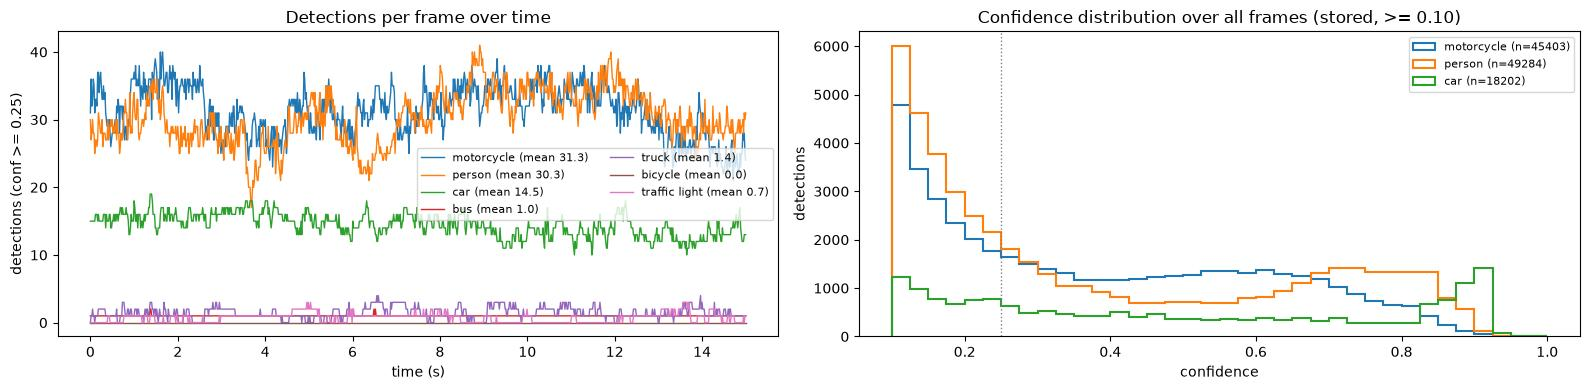

frames with a traffic light at conf >= 0.25: 519/900; at the stored threshold 0.10: 899/900
person boxes overlapping a two-wheeler (>= 30% of area), all frames: 16067/27258


In [14]:
times_s = np.arange(len(per_frame_counts)) / sample_meta["fps"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for name in ["motorcycle", "person", "car", "bus", "truck", "bicycle", "traffic light"]:
    series = [c[name] for c in per_frame_counts]
    axes[0].plot(times_s, series, label=f"{name} (mean {np.mean(series):.1f})", linewidth=1)
axes[0].set(xlabel="time (s)", ylabel=f"detections (conf >= {DISPLAY_CONF})", title="Detections per frame over time")
axes[0].legend(fontsize=8, ncol=2)

all_detections = [json.loads(line)["detections"] for line in detections_path.read_text().splitlines()]
for name in ["motorcycle", "person", "car"]:
    confidences = [d["confidence"] for frame_dets in all_detections for d in frame_dets if d["class_name"] == name]
    axes[1].hist(confidences, bins=36, range=(0.1, 1.0), histtype="step", linewidth=1.5, label=f"{name} (n={len(confidences)})")
axes[1].axvline(DISPLAY_CONF, color="grey", linestyle=":", linewidth=1)
axes[1].set(xlabel="confidence", ylabel="detections", title="Confidence distribution over all frames (stored, >= 0.10)")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "detections_over_time.png", dpi=100)
plt.show()

frames_with_light = sum(1 for c in per_frame_counts if c["traffic light"] > 0)
light_any = sum(1 for dets in all_detections if any(d["class_name"] == "traffic light" for d in dets))
print(f"frames with a traffic light at conf >= {DISPLAY_CONF}: {frames_with_light}/{len(per_frame_counts)}; "
      f"at the stored threshold 0.10: {light_any}/{len(per_frame_counts)}")
riders_total = [rider_share(dets) for dets in all_detections]
print(f"person boxes overlapping a two-wheeler (>= 30% of area), all frames: "
      f"{sum(r for r, _ in riders_total)}/{sum(p for _, p in riders_total)}")

### Traffic lights: localized, but without a state

The COCO class `traffic light` says *where* a signal head is, not *which lamp is lit*. We plot the center of every stored traffic-light box (confidence ≥ 0.10) over a frame, colored by confidence. Clusters show where the detector repeatedly finds signal heads.

traffic-light boxes (conf >= 0.10): 2777 in 899 of 900 frames


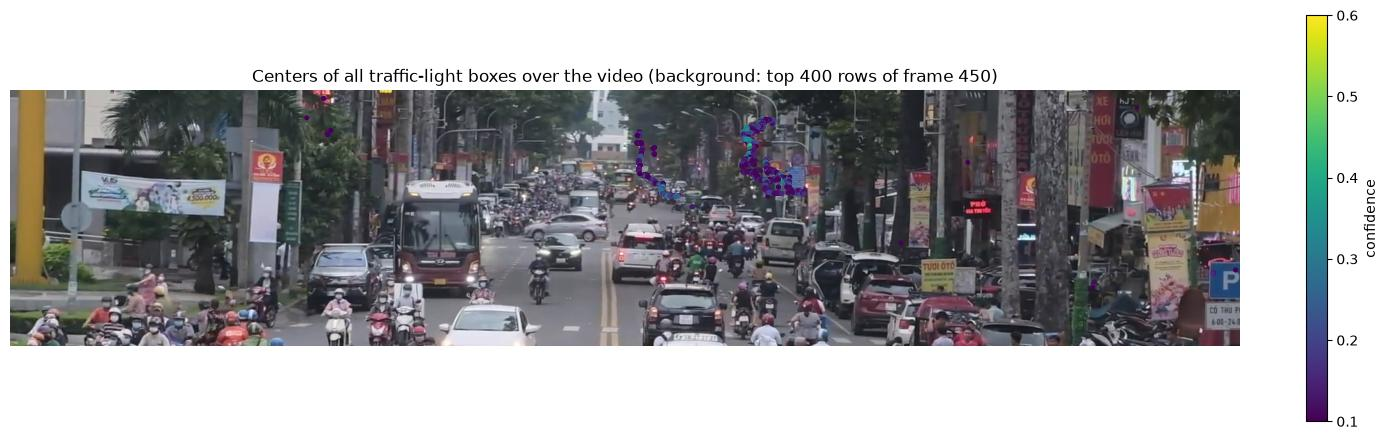

In [15]:
lights = [(k, d) for k, dets in enumerate(all_detections) for d in dets if d["class_name"] == "traffic light"]
light_xy = np.array([[(d["bbox_xyxy"][0] + d["bbox_xyxy"][2]) / 2, (d["bbox_xyxy"][1] + d["bbox_xyxy"][3]) / 2] for _, d in lights])
light_conf = np.array([d["confidence"] for _, d in lights])
print(f"traffic-light boxes (conf >= 0.10): {len(lights)} in {len({k for k, _ in lights})} of {len(all_detections)} frames")

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.imshow(cv2.cvtColor(frame[0:400], cv2.COLOR_BGR2RGB))
points = ax.scatter(light_xy[:, 0], light_xy[:, 1], c=light_conf, s=6, cmap="viridis", vmin=0.1, vmax=0.6)
fig.colorbar(points, ax=ax, fraction=0.02, label="confidence")
ax.set_title("Centers of all traffic-light boxes over the video (background: top 400 rows of frame 450)")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "traffic_light_positions.jpg", dpi=100)
plt.show()

signal cluster x (1100, 1300): 2259 boxes; present in 890 frames at conf >= 0.10, 485 frames at conf >= 0.25
median confidence 0.18, median size 27 x 20 px


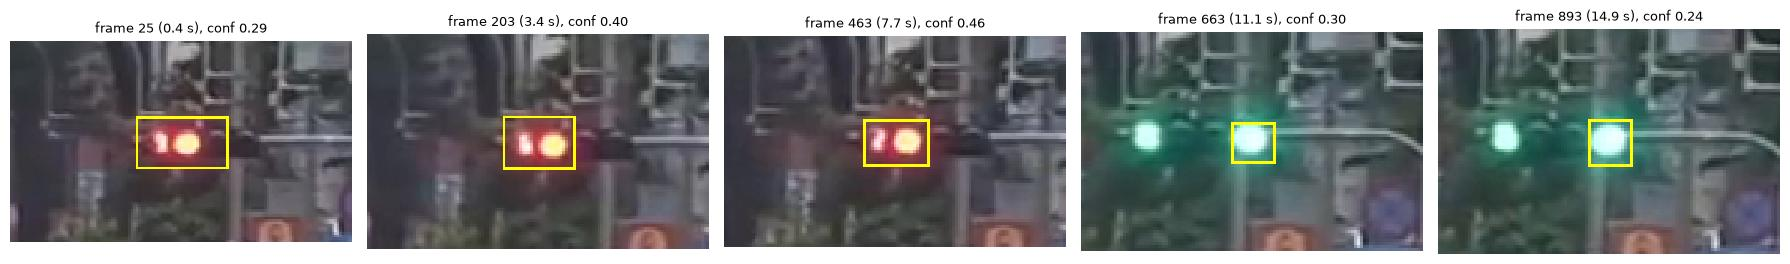

In [16]:
SIGNAL_X = (1100, 1300)  # x-range of the main cluster above: the signal head from Notebook 00
in_signal = [(k, d) for (k, d), (x, _) in zip(lights, light_xy) if SIGNAL_X[0] <= x < SIGNAL_X[1]]
widths = [d["bbox_xyxy"][2] - d["bbox_xyxy"][0] for _, d in in_signal]
heights = [d["bbox_xyxy"][3] - d["bbox_xyxy"][1] for _, d in in_signal]
signal_frames_any = {k for k, _ in in_signal}
signal_frames_display = {k for k, d in in_signal if d["confidence"] >= DISPLAY_CONF}
print(f"signal cluster x {SIGNAL_X}: {len(in_signal)} boxes; present in {len(signal_frames_any)} frames at conf >= 0.10, "
      f"{len(signal_frames_display)} frames at conf >= {DISPLAY_CONF}")
print(f"median confidence {np.median([d['confidence'] for _, d in in_signal]):.2f}, median size {np.median(widths):.0f} x {np.median(heights):.0f} px")

# The best signal box near five moments of the clip, enlarged: is the lit lamp visible inside the box?
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, t in zip(axes, [0.0, 3.8, 7.5, 11.2, 15.0]):
    target = min(int(round(t * sample_meta["fps"])), len(all_detections) - 1)
    nearby = [(k, d) for k, d in in_signal if abs(k - target) <= 30]
    if not nearby:
        ax.set_title(f"t={t:.1f} s: no signal box within 0.5 s", fontsize=9)
        ax.axis("off")
        continue
    k, d = max(nearby, key=lambda kd: kd[1]["confidence"])
    x1, y1, x2, y2 = (int(round(v)) for v in d["bbox_xyxy"])
    image = read_frame_at(SAMPLE_VIDEO, k)["image"]
    crop = image[max(0, y1 - 30):y2 + 30, max(0, x1 - 50):x2 + 50].copy()
    cv2.rectangle(crop, (x1 - max(0, x1 - 50), y1 - max(0, y1 - 30)), (x2 - max(0, x1 - 50), y2 - max(0, y1 - 30)), (0, 255, 255), 1)
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(f"frame {k} ({k / sample_meta['fps']:.1f} s), conf {d['confidence']:.2f}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "traffic_light_crops.jpg", dpi=100)
plt.show()

### Stability across consecutive frames

A tracker relies on objects being detected in *consecutive* frames. A quick visual check: the same zoomed region over six consecutive frames. Boxes that appear and disappear between frames ("flicker") show up here before they show up as broken tracks.

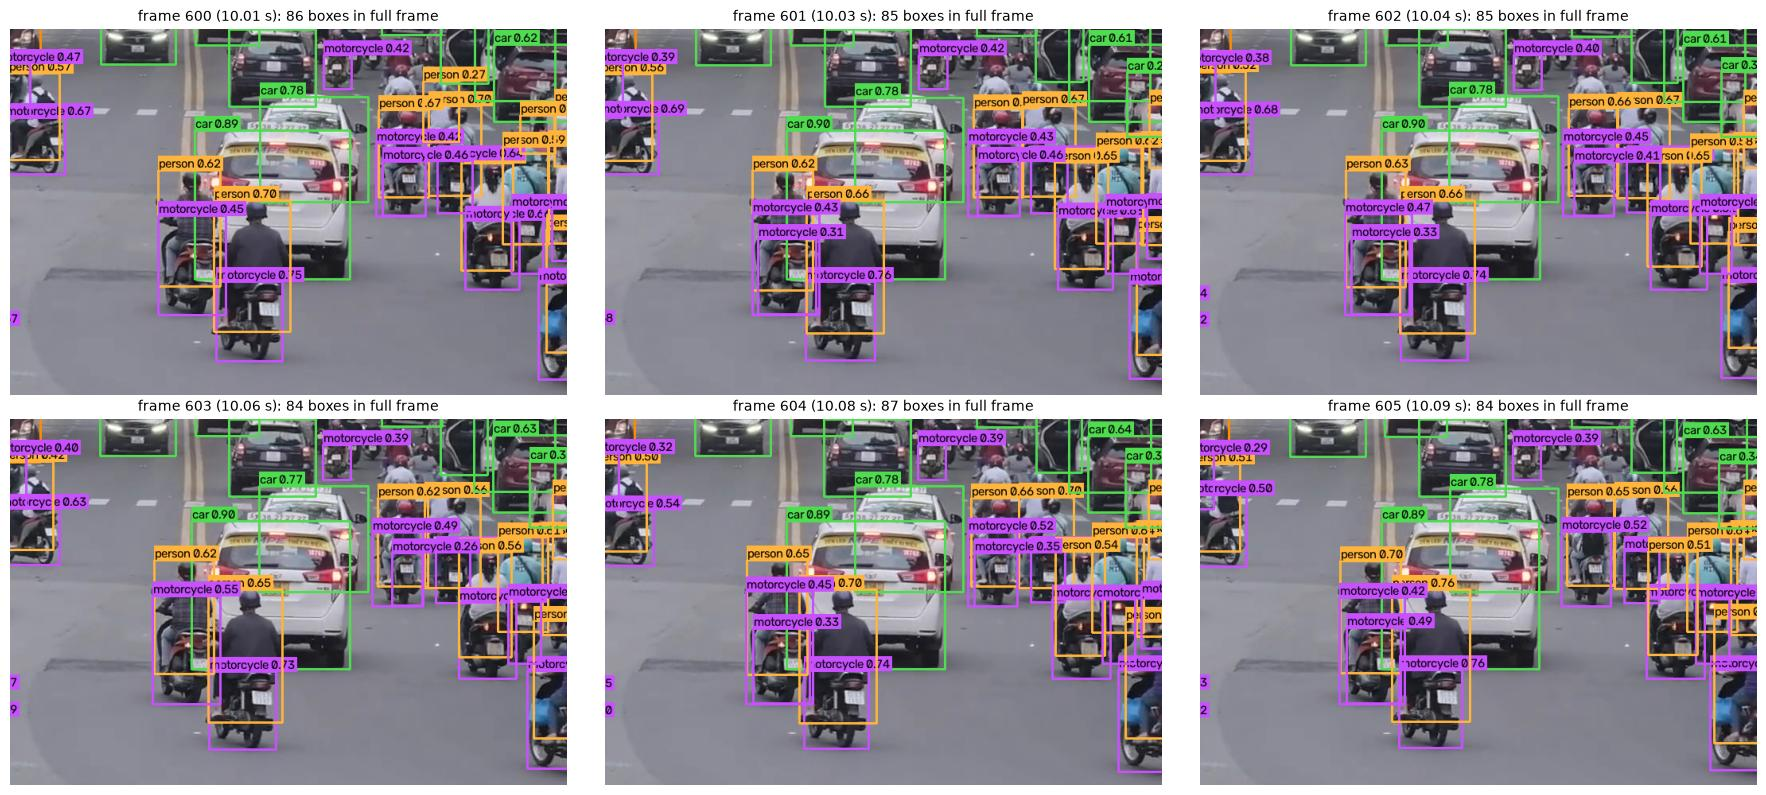

boxes per frame (conf >= 0.25): mean 79.2, min 64, max 96
frame-to-frame change in box count: median 2, 95th percentile 6, max 9


In [17]:
FLICKER_START, FLICKER_REGION = 600, (slice(300, 760), slice(700, 1400))
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, k in zip(axes.ravel(), range(FLICKER_START, FLICKER_START + 6)):
    dets = all_detections[k]
    image = read_frame_at(SAMPLE_VIDEO, k)["image"]
    shown = sum(1 for d in dets if d["confidence"] >= DISPLAY_CONF)
    ax.imshow(cv2.cvtColor(draw_detections(image, dets)[FLICKER_REGION], cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {k} ({k / sample_meta['fps']:.2f} s): {shown} boxes in full frame", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "consecutive_frames.jpg", dpi=90)
plt.show()

counts_total = np.array([sum(c.values()) for c in per_frame_counts])
step_change = np.abs(np.diff(counts_total))
print(f"boxes per frame (conf >= {DISPLAY_CONF}): mean {counts_total.mean():.1f}, min {counts_total.min()}, max {counts_total.max()}")
print(f"frame-to-frame change in box count: median {np.median(step_change):.0f}, 95th percentile {np.percentile(step_change, 95):.0f}, max {step_change.max()}")

## 7. Validation

In [18]:
records = [json.loads(line) for line in detections_path.read_text().splitlines()]
W, H = sample_meta["width"], sample_meta["height"]
all_dets = [d for r in records for d in r["detections"]]

repeat = detect(model, frame, DETECTOR_CONFIG)
same_classes = [d["class_id"] for d in repeat] == [d["class_id"] for d in detections]
max_box_diff = (float(np.abs(np.array([d["bbox_xyxy"] for d in repeat]) - np.array([d["bbox_xyxy"] for d in detections])).max())
                if same_classes and repeat else float("inf"))

checks = {
    "one record per decoded frame, indices 0..N-1": [r["frame_index"] for r in records] == list(range(sample_meta["reported_frame_count"])),
    "records carry the Frame Data fields": all({"video_id", "frame_index", "timestamp_s", "width", "height", "detections"} <= set(r) for r in records),
    "every detection has the Detection Data fields": all(set(d) == {"class_id", "class_name", "confidence", "bbox_xyxy"} for d in all_dets),
    "boxes lie inside the frame and have positive size": all(
        -0.5 <= d["bbox_xyxy"][0] < d["bbox_xyxy"][2] <= W + 0.5 and -0.5 <= d["bbox_xyxy"][1] < d["bbox_xyxy"][3] <= H + 0.5 for d in all_dets),
    "confidences within [stored threshold, 1]": all(DETECTOR_CONFIG["conf"] <= d["confidence"] <= 1 for d in all_dets),
    "only the selected traffic classes": {d["class_id"] for d in all_dets} <= set(DETECTOR_CONFIG["classes"]),
    "class names consistent with model.names": all(model.names[d["class_id"]] == d["class_name"] for d in all_dets),
    "repeated inference on a frame gives the same result (< 0.05 px)": same_classes and max_box_diff < 0.05,
    "own NMS reproduces >= 95% of the detector's boxes": nms_agreement >= 0.95,
    "annotated video has one frame per input frame": read_video_metadata(annotated_video_path)["reported_frame_count"] == len(records),
}
for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
print(f"(repeat-inference max box difference: {max_box_diff:.4f} px; NMS agreement {nms_agreement:.1%})")
assert all(checks.values()), "One or more checks failed - see above"

[PASS] one record per decoded frame, indices 0..N-1
[PASS] records carry the Frame Data fields
[PASS] every detection has the Detection Data fields
[PASS] boxes lie inside the frame and have positive size
[PASS] confidences within [stored threshold, 1]
[PASS] only the selected traffic classes
[PASS] class names consistent with model.names
[PASS] repeated inference on a frame gives the same result (< 0.05 px)
[PASS] own NMS reproduces >= 95% of the detector's boxes
[PASS] annotated video has one frame per input frame
(repeat-inference max box difference: 0.0000 px; NMS agreement 100.0%)


## 8. Performance summary

In [19]:
summary = {
    "frames": len(records),
    "end_to_end_fps": len(records) / total_seconds,
    "median_ms": {stage: statistics.median(v) for stage, v in stage_ms.items()},
    "detections_per_frame_mean": float(np.mean(counts_total)),
    "mean_per_class": {name: float(np.mean([c[name] for c in per_frame_counts])) for name in TRAFFIC_CLASSES.values()},
    "model_comparison": comparison,
    "nms_agreement": nms_agreement,
    "checks": checks,
}
(OUTPUT_DIR / "detection_summary.json").write_text(json.dumps(summary, indent=2))

budget_ms = 1000 / sample_meta["fps"]
model_ms = sum(summary["median_ms"].values())
print(f"real-time budget per frame at {sample_meta['fps']:.2f} FPS : {budget_ms:.1f} ms")
print(f"detector (pre + inference + post), median     : {model_ms:.1f} ms")
print(f"end to end incl. decode and writing           : {1000 / summary['end_to_end_fps']:.1f} ms per frame "
      f"({summary['end_to_end_fps']:.1f} FPS)")
print("Wrote", (OUTPUT_DIR / "detection_summary.json").relative_to(PROJECT_ROOT))

real-time budget per frame at 59.94 FPS : 16.7 ms
detector (pre + inference + post), median     : 14.9 ms
end to end incl. decode and writing           : 29.2 ms per frame (34.3 FPS)
Wrote outputs/02_object_detection/detection_summary.json


## 9. From any video to a video with its boxes

Everything above studies one sample video. The step is now also one function, in `src/traffic_violation_detection/detection.py`, that works on any video:

```python
from traffic_violation_detection.detection import annotate_video

output_path = annotate_video("path/to/video.mp4", "path/to/output_folder")
# -> path/to/output_folder/video_output.mp4
```

- It uses the detector settings and drawing style chosen in this notebook, and draws boxes with confidence ≥ 0.25.
- The output has the size and frame rate of the input. The video in section 7 was reduced to half size to save space.
- It is H.264, which common players and browsers can open.
- It is for viewing. Later steps should read the original video and the stored detections, because drawn boxes cover what they need to see.

**Checking it.** At the five frames used earlier, the output should match this notebook's own drawing of the detections stored in section 7. The comparison uses brightness, because the 4:2:0 colour format of H.264 lowers the PSNR of thin saturated lines to about 30 dB by itself, with no compression at all. To show the check can fail, the output is also compared with the boxes of another frame, and with no boxes.

In [20]:
from traffic_violation_detection.detection import annotate_video


def psnr(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 99.0 if mse == 0 else 10 * np.log10(255**2 / mse)


start = time.perf_counter()
output_video = annotate_video(SAMPLE_VIDEO, OUTPUT_DIR)
elapsed = time.perf_counter() - start

output_meta = read_video_metadata(output_video)
frames_written = sum(1 for _ in iter_frames(output_video))
print(f"{output_video.relative_to(PROJECT_ROOT)}: {output_video.stat().st_size / 1e6:.1f} MB, {elapsed:.0f} s for {frames_written} frames")
print(f"input : {sample_meta['width']}x{sample_meta['height']}, {sample_meta['fps']:.2f} FPS, {sample_meta['reported_frame_count']} frames")
print(f"output: {output_meta['width']}x{output_meta['height']}, {output_meta['fps']:.2f} FPS, {frames_written} frames")
assert frames_written == sample_meta["reported_frame_count"]
assert (output_meta["width"], output_meta["height"]) == (sample_meta["width"], sample_meta["height"])

stored = [json.loads(line) for line in detections_path.open()]


def brightness(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


print(f"\nPSNR of the output's brightness, in dB\n{'frame':>6}{'this frame boxes':>18}{'boxes of frame +60':>20}{'no boxes':>10}")
for k in COMPARE_FRAMES:
    source_frame = read_frame_at(SAMPLE_VIDEO, k)["image"]
    output_frame = brightness(read_frame_at(output_video, k)["image"])
    same = psnr(output_frame, brightness(draw_detections(source_frame, stored[k]["detections"], thickness=3)))
    other = psnr(output_frame, brightness(draw_detections(source_frame, stored[(k + 60) % len(stored)]["detections"], thickness=3)))
    plain = psnr(output_frame, brightness(source_frame))
    print(f"{k:>6}{same:>18.1f}{other:>20.1f}{plain:>10.1f}")
    assert same >= 35 and same > other + 10 and same > plain + 10

half_size = cv2.resize(read_frame_at(output_video, FRAME_INDEX)["image"], video_size, interpolation=cv2.INTER_AREA)
print(f"\nframe {FRAME_INDEX}, against the half-size video of section 7: {psnr(brightness(half_size), brightness(read_frame_at(annotated_video_path, FRAME_INDEX)['image'])):.1f} dB")

outputs/02_object_detection/video-test_output.mp4: 38.7 MB, 49 s for 900 frames
input : 1920x1080, 59.94 FPS, 900 frames
output: 1920x1080, 59.94 FPS, 900 frames



PSNR of the output's brightness, in dB
 frame  this frame boxes  boxes of frame +60  no boxes
     0              37.4                16.8      19.1


   225              36.4                17.8      20.1


   450              37.1                17.6      19.7


   675              36.4                17.4      19.5


   899              36.1                17.7      20.5



frame 450, against the half-size video of section 7: 37.7 dB


**On another video.** A clip with a different size and frame rate. An already loaded detector can be passed in, so it is not loaded again for each video.

In [21]:
other_video = PROJECT_ROOT / "data" / "car-detection.mp4"
other_output = annotate_video(other_video, OUTPUT_DIR, model=model)
other_input_meta, other_output_meta = read_video_metadata(other_video), read_video_metadata(other_output)
other_frames = sum(1 for _ in iter_frames(other_output))
print(f"input : {other_video.name}: {other_input_meta['width']}x{other_input_meta['height']}, {other_input_meta['fps']:.2f} FPS, {other_input_meta['reported_frame_count']} frames")
print(f"output: {other_output.name}: {other_output_meta['width']}x{other_output_meta['height']}, {other_output_meta['fps']:.2f} FPS, {other_frames} frames, {other_output.stat().st_size / 1e6:.1f} MB")
assert other_frames == other_input_meta["reported_frame_count"]

input : car-detection.mp4: 768x432, 12.50 FPS, 377 frames
output: car-detection_output.mp4: 768x432, 12.50 FPS, 377 frames, 2.0 MB


## Results

### Model selection (5 frames, no ground truth)

- At `imgsz=1280`, every model reports about 1.5–2× as many motorcycles and persons as at `imgsz=640`. Model size (*s*/*m*/*l*) changes the counts much less.
- `yolo26m.pt` at `imgsz=1280` was chosen as a provisional baseline.

### Full video

Setup: 900 frames, `yolo26m.pt`, `imgsz=1280`, stored confidence ≥ 0.10, NMS IoU 0.7. Numbers are from the outputs above.

- **What is detected.** Per frame (confidence ≥ 0.25) there are on average about 31 motorcycles, 30 persons, 15 cars, 1–2 trucks, 1 bus, and no bicycles.
- **Stable counts.** The total stays between 64 and 96 boxes per frame, and the median change between consecutive frames is 2 boxes.
- **Long low-confidence tail.** Many motorcycle and person boxes score below 0.25; these are mostly small, distant or occluded road users. They are kept in the file (stored threshold 0.10) because trackers such as ByteTrack use low-score boxes to keep tracks alive.
- **Riders.** About 59% of all person boxes overlap a motorcycle or bicycle box by at least 30% of their area. Most persons in this scene are riders, not pedestrians.
- **Traffic signal.** The signal head studied in Notebook 00 is **localized in almost every frame** at confidence ≥ 0.10, and in about half of the frames at ≥ 0.25.
  - Its boxes are small (median ≈ 27×20 px) and have low confidence (median ≈ 0.18).
  - The box centers form an elongated trail rather than a point, because the camera drifts (Notebook 00).
  - The enlarged crops show the lit lamp inside the box. The detector provides the **position** of the signal; its **state** (red/green) must come from a separate step, for example color analysis inside the box. This makes a red-light rule more feasible than assumed in Notebook 00.
- **NMS understood.** On frame 450, the from-scratch NMS reproduced all of the detector's boxes.
- **Deterministic.** Repeated inference on the same frame gives identical boxes.
- **Performance on the RTX 4090.** Detection alone (preprocess + inference + postprocess, median) fits within the 16.7 ms real-time budget of a 59.94 FPS video. End to end, including decoding, JSON writing and the annotated video, the pipeline runs at the throughput reported in section 8. That figure is limited by single-frame processing and I/O, not by the network.

### Failure modes seen in the zoomed and consecutive frames

- **Far field.** Many small motorcycles in the dense queue toward the intersection are not boxed.
- **Class confusion.** Some vans and minivans are labelled `truck` with low confidence.
- **Nested duplicates.** A motorcycle sometimes gets two boxes, with and without its rider. Their IoU is below the NMS threshold, so both survive.
- **Parked vehicles.** Motorcycles parked on the right sidewalk are only partly detected.
- **Flicker.** Low-confidence boxes appear and disappear between consecutive frames, so a tracker must tolerate short gaps.

## Limitations

- **No ground truth.** Detection counts are not precision or recall, and the model choice is provisional until labeled frames are evaluated (Notebook 09).
- **COCO classes.** COCO distinguishes neither riders from pedestrians, nor traffic-light states, and has no license-plate class.
- **Narrow data.** One video, one camera, overcast daylight. The camera drift from Notebook 00 does not affect detection itself, but it does affect any fixed scene geometry.
- **Untuned settings.** Thresholds (stored 0.10, display 0.25, NMS IoU 0.7) are defaults, not tuned values. The rider heuristic's 30% threshold is arbitrary.
- **No speed optimizations.** Inference runs one frame at a time in FP32, without batching or FP16.
- **License.** Ultralytics is AGPL-3.0, which matters if this system is ever distributed or served (see section 2).

## Conclusion

**Completion criterion** — *the notebook consistently detects relevant traffic objects and produces structured detection results that can be consumed by a tracker*: **met for the baseline.**

- Every one of the 900 frames has a Detection Data record that passed the schema, bounds, and class checks.
- Detections are stable from frame to frame.
- The quality limits above are documented rather than assumed away.

**Readiness for integration.**

- `outputs/02_object_detection/detections/video-test.jsonl`, with its `.config.json`, is the input for Notebook 03.
- `annotate_video`, with `detect` and `draw_detections`, is now in `src/traffic_violation_detection/detection.py` with tests (section 9). It reproduces this notebook's detections and drawing: brightness PSNR is 36–37 dB against the notebook's own drawing at five frames, and 17–18 dB against the boxes of another frame. On `car-detection.mp4` it keeps the size and frame rate of a different video, though the detector can miss cars in that overhead view: frame 200 shows one with no box.

**Next: Notebook 03 — multi-object tracking.**

- Track vehicles (ByteTrack) from the stored detections, using the low-confidence boxes.
- Decide how to treat riders: likely as part of their motorcycle, not as separate road users.